# Análise consolidada — Rubrica 16 dim (Gemini + GPT-5-mini)

Consolida as avaliações dos dois juízes LLM em um único CSV e gera:
- **Table 1** — mean Likert score M (SD) by generator model, prompt strategy, and evaluator
- **Comparações não paramétricas** — Mann–Whitney U, Bonferroni, rank-biserial *r*, diferença absoluta Likert
- Heatmaps Likert **1–3** (dimensões de conteúdo) por juiz
- Heatmaps **gerais** (média entre juízes Gemini + GPT-5-mini)

In [22]:
import json
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from scipy.stats import mannwhitneyu

In [ ]:
CAMINHO_GEMINI = Path("..") / "resultado_rubrica" / "prova-tecnologia-results-1500-rubrica-16dim.csv"
CAMINHO_GPT = Path("..") / "resultado_rubrica" / "prova-tecnologia-results-1500-rubrica-16dim-gpt5mini.csv"
CAMINHO_CONSOLIDADO = (
    Path("..") / "resultado_rubrica" / "prova-tecnologia-results-1500-rubrica-16dim-consolidado.csv"
)

ROTULO_JUIZ = {
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "gpt-5-mini": "GPT-5-mini",
}

In [23]:
def carregar_e_rotular(caminho: Path, juiz: str) -> pd.DataFrame:
    if not caminho.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho.resolve()}")
    df = pd.read_csv(caminho)
    df["juiz"] = juiz
    return df


df_gemini = carregar_e_rotular(CAMINHO_GEMINI, "gemini-2.5-flash")
df_gpt = carregar_e_rotular(CAMINHO_GPT, "gpt-5-mini")

df_consolidado = pd.concat([df_gemini, df_gpt], ignore_index=True)

colunas = [
    "juiz",
    "modelo",
    "prompt_variant",
    "pergunta",
    "resposta_aluno",
    "explicacao",
    "disciplina",
    "feedback",
    "analise_feedback",
]
df_consolidado = df_consolidado[colunas]
df_consolidado.to_csv(CAMINHO_CONSOLIDADO, index=False, encoding="utf-8")

print(f"Consolidado salvo: {CAMINHO_CONSOLIDADO.resolve()}")
print(f"Linhas totais: {len(df_consolidado)} ({len(df_gemini)} Gemini + {len(df_gpt)} GPT)")
print(df_consolidado.groupby("juiz").size())
df_consolidado.head(3)

Consolidado salvo: C:\Users\anara\Desktop\Pesquisa - Tutoria\feedback-open-source\resultado_rubrica\prova-tecnologia-results-1500-rubrica-16dim-consolidado.csv
Linhas totais: 3000 (1500 Gemini + 1500 GPT)
juiz
gemini-2.5-flash    1500
gpt-5-mini          1500
dtype: int64


,juiz,modelo,prompt_variant,pergunta,resposta_aluno,explicacao,disciplina,feedback,analise_feedback
0,gemini-2.5-flash,phi4-mini,hattie,Quais são as principais características de um ...,"O SMP, que é tipo um sistema com vários proces...",Exatamente! A distribuição equilibrada da carg...,SUAP018548 - Arquitetura de Computadores:Bacha...,O aluno explicou corretamente que o SMP usa vá...,"{""conteudo"": {""alinhamento_objetivos"": {""score..."
1,gemini-2.5-flash,qwen3,base,O microfone é um dispositivo de entrada usado ...,Verdadeiro,Esta opção está correta . O microfone é um dis...,06262 - AG - INTRODUÇÃO À INFORMÁTICA,O aluno identificou corretamente que o microfo...,"{""conteudo"": {""alinhamento_objetivos"": {""score..."
2,gemini-2.5-flash,phi4-mini,hattie,Converta os números binários abaixo para decim...,a) 12b) 3c) 28d) 60e) 42,Correto! O número binário 011100 é igual a 28 ...,SUAP018548 - Arquitetura de Computadores:Bacha...,A resposta do aluno para a converção binária 0...,"{""conteudo"": {""alinhamento_objetivos"": {""score..."


In [24]:
DIMENSOES_CONTEUDO = [
    "alinhamento_objetivos",
    "especificidade",
    "tom_motivacional",
    "pontos_fortes",
    "pontos_fracos",
    "legibilidade",
]

# Table 1 — five content dimensions (excludes legibility, near-ceiling)
DIMENSOES_TABELA1 = [
    "alinhamento_objetivos",
    "especificidade",
    "tom_motivacional",
    "pontos_fortes",
    "pontos_fracos",
]

ROTULOS_DIMENSAO = {
    "alinhamento_objetivos": "Alignment with objectives",
    "especificidade": "Specificity",
    "tom_motivacional": "Motivational tone",
    "pontos_fortes": "Strengths identification",
    "pontos_fracos": "Weaknesses identification",
    "legibilidade": "Readability",
}

ROTULO_PROMPT = {"base": "Base", "nicol": "Nicol", "hattie": "Hattie"}


def extrair_scores_conteudo_likert(valor):
    """Extrai scores das 6 dimensões de conteúdo e converte 0–2 → Likert 1–3."""
    try:
        if pd.isna(valor):
            return None
        dados = json.loads(valor) if isinstance(valor, str) else valor
        if "erro" in dados:
            return None
        conteudo = dados.get("conteudo", {})
        scores = {}
        for dim in DIMENSOES_CONTEUDO:
            info = conteudo.get(dim)
            if info is None and dim == "pontos_fracos":
                info = conteudo.get("pontos_fraços")
            if info is None:
                return None
            scores[dim] = info["score"] + 1
        return scores
    except Exception:
        return None


def extrair_average_score(valor):
    """Média das 16 dimensões normalizada para escala 0–2."""
    try:
        if pd.isna(valor):
            return None
        dados = json.loads(valor) if isinstance(valor, str) else valor
        if "erro" in dados:
            return None
        scores = []
        for info in dados.get("conteudo", {}).values():
            scores.append(info["score"])
        for info in dados.get("efetividade", {}).values():
            scores.append(info["score"] * 2)
        for info in dados.get("alucinacoes", {}).values():
            scores.append((1 - info["score"]) * 2)
        return sum(scores) / len(scores) if scores else None
    except Exception:
        return None


def heatmap_conteudo(pivot, titulo, ax, xlabel="Content dimension", ylabel=""):
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="YlOrRd",
        vmin=1,
        vmax=3,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Mean Likert score (1–3)"},
        ax=ax,
    )
    ax.set_title(titulo, fontsize=11, pad=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=9)


def heatmap_average_score(pivot, titulo, ax, vmin=0, vmax=2, xlabel="", ylabel=""):
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Mean score (0–2)"},
        ax=ax,
    )
    ax.set_title(titulo, fontsize=11, pad=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=9)


def pivot_average_score_modelo_prompt(df_sub):
    tabela = (
        df_sub.dropna(subset=["average_score"])
        .groupby(["modelo", "rubrica"], as_index=False)["average_score"]
        .mean()
    )
    pivot = tabela.pivot(index="modelo", columns="rubrica", values="average_score")
    return pivot.reindex(columns=["Base", "Nicol", "Hattie"])


def pivot_likert(df_long_sub, index_col):
    pivot = (
        df_long_sub.groupby([index_col, "dimensao"])["likert"]
        .mean()
        .unstack("dimensao")[DIMENSOES_CONTEUDO]
    )
    pivot.columns = [ROTULOS_DIMENSAO[c] for c in pivot.columns]
    if index_col == "prompt":
        pivot = pivot.reindex(["Base", "Nicol", "Hattie"])
    return pivot


def formato_m_dp(media, dp):
    if pd.isna(media):
        return ""
    if pd.isna(dp):
        return f"{media:.2f}"
    return f"{media:.2f} ({dp:.2f})"


def construir_tabela1(df_in):
    """Table 1: M (SD) for five content dimensions, by model × prompt × evaluator."""
    base = df_in.copy()
    base["prompt"] = base["prompt_variant"].astype(str).str.lower().map(ROTULO_PROMPT)
    base["avaliador"] = base["juiz"].map(ROTULO_JUIZ)

    linhas = []
    for _, row in base.iterrows():
        scores = extrair_scores_conteudo_likert(row["analise_feedback"])
        if scores is None:
            continue
        for dim in DIMENSOES_TABELA1:
            linhas.append(
                {
                    "modelo": row["modelo"],
                    "prompt": row["prompt"],
                    "avaliador": row["avaliador"],
                    "dimensao": dim,
                    "likert": scores[dim],
                }
            )

    long_df = pd.DataFrame(linhas)
    stats = (
        long_df.groupby(["modelo", "prompt", "avaliador", "dimensao"], as_index=False)["likert"]
        .agg(media="mean", dp="std", n="count")
    )
    stats["M_DP"] = stats.apply(lambda r: formato_m_dp(r["media"], r["dp"]), axis=1)

    tabela1 = (
        stats.pivot(index=["modelo", "prompt", "avaliador"], columns="dimensao", values="M_DP")
        .reindex(columns=DIMENSOES_TABELA1)
    )
    tabela1.columns = [ROTULOS_DIMENSAO[c] for c in tabela1.columns]

    ordem_prompt = ["Base", "Nicol", "Hattie"]
    ordem_avaliador = [ROTULO_JUIZ["gemini-2.5-flash"], ROTULO_JUIZ["gpt-5-mini"]]
    tabela1 = tabela1.reset_index()
    tabela1["prompt"] = pd.Categorical(tabela1["prompt"], categories=ordem_prompt, ordered=True)
    tabela1["avaliador"] = pd.Categorical(tabela1["avaliador"], categories=ordem_avaliador, ordered=True)
    tabela1 = tabela1.sort_values(["modelo", "prompt", "avaliador"]).reset_index(drop=True)

    tabela1 = tabela1.rename(
        columns={
            "modelo": "Generator model",
            "prompt": "Prompt strategy",
            "avaliador": "Evaluator",
        }
    )
    return tabela1, stats, long_df


ROTULO_MODELO = {
    "gemma4": "Gemma4",
    "qwen3": "Qwen3",
    "phi4-mini": "Phi4-mini",
}


def formatar_pvalor(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "p < 0,001"
    return f"p = {p:.3f}".replace(".", ",")


def rank_biserial(u, n1, n2):
    """Rank-biserial correlation from Mann–Whitney U (group 1 vs group 2)."""
    if n1 == 0 or n2 == 0:
        return np.nan
    return 1 - (2 * u) / (n1 * n2)


def mannwhitney_completo(a, b):
    a = pd.Series(a).dropna().astype(float)
    b = pd.Series(b).dropna().astype(float)
    if len(a) < 2 or len(b) < 2:
        return None
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    return {
        "U": u,
        "p": p,
        "r": rank_biserial(u, len(a), len(b)),
        "M_a": a.mean(),
        "M_b": b.mean(),
        "diff_likert": abs(a.mean() - b.mean()),
        "n_a": len(a),
        "n_b": len(b),
    }


def comparacoes_pareadas_mannwhitney(long_df, group_col, estratos, pares=None, alpha=0.05):
    """Pairwise Mann–Whitney U with Bonferroni correction across all tests."""
    if pares is None:
        pares = list(combinations(sorted(long_df[group_col].dropna().unique()), 2))

    linhas = []
    for estrato_vals, sub in long_df.groupby(list(estratos), dropna=False):
        if not isinstance(estrato_vals, tuple):
            estrato_vals = (estrato_vals,)
        for g1, g2 in pares:
            res = mannwhitney_completo(
                sub.loc[sub[group_col] == g1, "likert"],
                sub.loc[sub[group_col] == g2, "likert"],
            )
            if res is None:
                continue
            row = dict(zip(estratos, estrato_vals))
            row.update({"grupo_a": g1, "grupo_b": g2, **res})
            linhas.append(row)

    tab = pd.DataFrame(linhas)
    if tab.empty:
        return tab

    n_testes = len(tab)
    tab["p_bonferroni"] = (tab["p"] * n_testes).clip(upper=1.0)
    tab["significativo"] = tab["p_bonferroni"] < alpha
    tab["p_fmt"] = tab["p"].map(formatar_pvalor)
    tab["p_bonf_fmt"] = tab["p_bonferroni"].map(formatar_pvalor)
    tab["r_abs"] = tab["r"].abs()
    tab["n_testes_bonferroni"] = n_testes
    return tab


def formatar_tabela_comparacoes(tab):
    if tab.empty:
        return tab
    out = tab.copy()
    out["dimensao"] = out["dimensao"].map(ROTULOS_DIMENSAO)
    if "modelo" in out.columns:
        out["modelo"] = out["modelo"].map(ROTULO_MODELO)
    out["grupo_a"] = out["grupo_a"].map(lambda x: ROTULO_MODELO.get(x, ROTULO_PROMPT.get(x, x)))
    out["grupo_b"] = out["grupo_b"].map(lambda x: ROTULO_MODELO.get(x, ROTULO_PROMPT.get(x, x)))
    cols = [
        "dimensao",
        "avaliador",
        "grupo_a",
        "grupo_b",
        "n_a",
        "n_b",
        "M_a",
        "M_b",
        "diff_likert",
        "U",
        "r_abs",
        "p_fmt",
        "p_bonf_fmt",
        "significativo",
    ]
    if "modelo" in out.columns:
        cols.insert(2, "modelo")
    if "prompt" in out.columns:
        cols.insert(2, "prompt")
    cols = [c for c in cols if c in out.columns]
    return out[cols].rename(
        columns={
            "dimensao": "Content dimension",
            "avaliador": "Evaluator",
            "modelo": "Generator model (stratum)",
            "prompt": "Prompt strategy (stratum)",
            "grupo_a": "Group A",
            "grupo_b": "Group B",
            "M_a": "Mean A",
            "M_b": "Mean B",
            "diff_likert": "|Δ| Likert",
            "r_abs": "Rank-biserial |r|",
            "p_fmt": "p-value",
            "p_bonf_fmt": "p-value (Bonferroni)",
            "significativo": "Significant",
        }
    )



## Tabela 1 — Escore médio das dimensões de conteúdo M (DP)

Escala Likert (1–3), por **modelo gerador**, **estratégia de prompt** e **avaliador**.

In [25]:
df = pd.read_csv(CAMINHO_CONSOLIDADO)

tabela1, stats_tabela1, long_tabela1 = construir_tabela1(df)

print(
    "Tabela 1. Escore médio das cinco dimensões de conteúdo em escala Likert (1–3), "
    "no formato M (DP), por modelo gerador, estratégia de prompt e avaliador."
)
display(tabela1)

CAMINHO_TABELA1 = Path("..") / "resultado_rubrica" / "tabela1-conteudo-likert-m-dp.csv"
tabela1.to_csv(CAMINHO_TABELA1, index=False, encoding="utf-8")
print(f"\nExported: {CAMINHO_TABELA1.resolve()}")
print(f"Groups: {len(tabela1)} | Observations (long): {len(long_tabela1)}")

Tabela 1. Escore médio das cinco dimensões de conteúdo em escala Likert (1–3), no formato M (DP), por modelo gerador, estratégia de prompt e avaliador.


,Generator model,Prompt strategy,Evaluator,Alignment with objectives,Specificity,Motivational tone,Strengths identification,Weaknesses identification
0,gemma4,Base,Gemini 2.5 Flash,2.80 (0.56),2.66 (0.60),2.84 (0.43),2.69 (0.72),2.75 (0.62)
1,gemma4,Base,GPT-5-mini,2.89 (0.42),2.39 (0.54),2.97 (0.18),2.65 (0.72),2.90 (0.37)
2,gemma4,Nicol,Gemini 2.5 Flash,2.91 (0.37),2.69 (0.48),2.99 (0.09),2.79 (0.60),2.72 (0.64)
3,gemma4,Nicol,GPT-5-mini,2.94 (0.35),2.30 (0.46),2.99 (0.08),2.79 (0.56),2.90 (0.38)
4,gemma4,Hattie,Gemini 2.5 Flash,2.88 (0.42),2.72 (0.51),2.83 (0.38),2.57 (0.80),2.72 (0.66)
5,gemma4,Hattie,GPT-5-mini,2.97 (0.18),2.35 (0.50),2.89 (0.31),2.57 (0.81),2.95 (0.24)
6,phi4-mini,Base,Gemini 2.5 Flash,2.83 (0.54),2.50 (0.59),2.73 (0.46),2.79 (0.57),2.79 (0.57)
7,phi4-mini,Base,GPT-5-mini,2.90 (0.41),2.19 (0.44),2.90 (0.32),2.68 (0.58),2.92 (0.31)
8,phi4-mini,Nicol,Gemini 2.5 Flash,2.80 (0.58),2.38 (0.63),2.76 (0.44),2.72 (0.67),2.68 (0.68)
9,phi4-mini,Nicol,GPT-5-mini,2.92 (0.33),2.17 (0.39),2.90 (0.31),2.53 (0.67),2.84 (0.43)



Exported: C:\Users\anara\Desktop\Pesquisa - Tutoria\feedback-open-source\resultado_rubrica\tabela1-conteudo-likert-m-dp.csv
Groups: 18 | Observations (long): 13740


## Comparações não paramétricas (Mann–Whitney U)

Para cada par de grupos independentes, calculamos:

- **Mann–Whitney U** — teste não paramétrico (escala Likert 1–3)
- **Correção de Bonferroni** — ajuste do p-valor pelo número total de comparações na família de testes
- **Rank-biserial *r*** — tamanho de efeito
- **|Δ| Likert** — diferença absoluta entre as médias (magnitude prática)

Comparações par a par entre **modelos geradores** (estratificado por dimensão e avaliador; prompts agrupados) e entre **estratégias de prompt** (estratificado por dimensão, avaliador e modelo).

In [26]:
if "long_tabela1" not in globals():
    _, _, long_tabela1 = construir_tabela1(df)

pares_modelos = list(combinations(["gemma4", "qwen3", "phi4-mini"], 2))
pares_prompts = list(combinations(["Base", "Nicol", "Hattie"], 2))

# Modelos: pool prompts dentro de (dimensão × avaliador)
cmp_modelos = comparacoes_pareadas_mannwhitney(
    long_tabela1,
    group_col="modelo",
    estratos=["dimensao", "avaliador"],
    pares=pares_modelos,
)

# Prompts: pool observações dentro de (dimensão × avaliador × modelo)
cmp_prompts = comparacoes_pareadas_mannwhitney(
    long_tabela1,
    group_col="prompt",
    estratos=["dimensao", "avaliador", "modelo"],
    pares=pares_prompts,
)

tab_modelos = formatar_tabela_comparacoes(cmp_modelos)
tab_prompts = formatar_tabela_comparacoes(cmp_prompts)

print("=== Comparações par a par — modelos geradores ===")
print(
    f"Família de testes: {len(cmp_modelos)} comparações | "
    f"α Bonferroni = 0,05/{len(cmp_modelos)} = {0.05 / len(cmp_modelos):.4f}"
)
print(f"Significativas (Bonferroni): {cmp_modelos['significativo'].sum()}\n")
display(tab_modelos.round({"Mean A": 3, "Mean B": 3, "|Δ| Likert": 3, "Rank-biserial |r|": 3}))

print("\n=== Comparações par a par — estratégias de prompt ===")
print(
    f"Família de testes: {len(cmp_prompts)} comparações | "
    f"α Bonferroni = 0,05/{len(cmp_prompts)} = {0.05 / len(cmp_prompts):.4f}"
)
print(f"Significativas (Bonferroni): {cmp_prompts['significativo'].sum()}\n")
display(tab_prompts.round({"Mean A": 3, "Mean B": 3, "|Δ| Likert": 3, "Rank-biserial |r|": 3}))

# Resumo: diferenças práticas mais relevantes entre modelos
resumo_modelos = (
    cmp_modelos.sort_values("diff_likert", ascending=False)
    .assign(
        comparacao=lambda d: d["grupo_a"].map(ROTULO_MODELO)
        + " vs "
        + d["grupo_b"].map(ROTULO_MODELO),
        dimensao_label=lambda d: d["dimensao"].map(ROTULOS_DIMENSAO),
    )
    .loc[
        :,
        [
            "comparacao",
            "dimensao_label",
            "avaliador",
            "diff_likert",
            "r_abs",
            "p_fmt",
            "p_bonf_fmt",
            "significativo",
        ],
    ]
    .head(10)
)
print("\n=== Top 10 diferenças práticas (|Δ| Likert) — modelos ===")
display(resumo_modelos.round({"diff_likert": 3, "r_abs": 3}).rename(columns={"r_abs": "|r|"}))

CAMINHO_CMP_MODELOS = Path("..") / "resultado_rubrica" / "comparacoes-modelos-mannwhitney.csv"
CAMINHO_CMP_PROMPTS = Path("..") / "resultado_rubrica" / "comparacoes-prompts-mannwhitney.csv"
tab_modelos.to_csv(CAMINHO_CMP_MODELOS, index=False, encoding="utf-8")
tab_prompts.to_csv(CAMINHO_CMP_PROMPTS, index=False, encoding="utf-8")
print(f"\nExported: {CAMINHO_CMP_MODELOS.resolve()}")
print(f"Exported: {CAMINHO_CMP_PROMPTS.resolve()}")

=== Comparações par a par — modelos geradores ===
Família de testes: 30 comparações | α Bonferroni = 0,05/30 = 0.0017
Significativas (Bonferroni): 14



,Content dimension,Evaluator,Group A,Group B,n_a,n_b,Mean A,Mean B,|Δ| Likert,U,Rank-biserial |r|,p-value,p-value (Bonferroni),Significant
0,Alignment with objectives,GPT-5-mini,Gemma4,Qwen3,499,500,2.934,2.932,0.002,125216.0,0.004,"p = 0,779","p = 1,000",False
1,Alignment with objectives,GPT-5-mini,Gemma4,Phi4-mini,499,500,2.934,2.866,0.068,130472.0,0.046,"p = 0,004","p = 0,114",False
2,Alignment with objectives,GPT-5-mini,Qwen3,Phi4-mini,500,500,2.932,2.866,0.066,130289.0,0.042,"p = 0,008","p = 0,251",False
3,Alignment with objectives,Gemini 2.5 Flash,Gemma4,Qwen3,415,419,2.865,2.900,0.035,84635.0,0.027,"p = 0,148","p = 1,000",False
4,Alignment with objectives,Gemini 2.5 Flash,Gemma4,Phi4-mini,415,415,2.865,2.764,0.101,90300.0,0.049,"p = 0,027","p = 0,802",False
5,Alignment with objectives,Gemini 2.5 Flash,Qwen3,Phi4-mini,419,415,2.900,2.764,0.136,93377.5,0.074,"p < 0,001","p = 0,010",True
6,Specificity,GPT-5-mini,Gemma4,Qwen3,499,500,2.347,2.148,0.199,148634.5,0.191,"p < 0,001","p < 0,001",True
7,Specificity,GPT-5-mini,Gemma4,Phi4-mini,499,500,2.347,2.150,0.197,148734.0,0.192,"p < 0,001","p < 0,001",True
8,Specificity,GPT-5-mini,Qwen3,Phi4-mini,500,500,2.148,2.150,0.002,124904.5,0.001,"p = 0,976","p = 1,000",False
9,Specificity,Gemini 2.5 Flash,Gemma4,Qwen3,415,419,2.692,2.463,0.229,105445.5,0.213,"p < 0,001","p < 0,001",True



=== Comparações par a par — estratégias de prompt ===
Família de testes: 90 comparações | α Bonferroni = 0,05/90 = 0.0006
Significativas (Bonferroni): 11



,Content dimension,Evaluator,Generator model (stratum),Group A,Group B,n_a,n_b,Mean A,Mean B,|Δ| Likert,U,Rank-biserial |r|,p-value,p-value (Bonferroni),Significant
0,Alignment with objectives,GPT-5-mini,Gemma4,Base,Nicol,156,163,2.891,2.939,0.048,12220.0,0.039,"p = 0,113","p = 1,000",False
1,Alignment with objectives,GPT-5-mini,Gemma4,Base,Hattie,156,180,2.891,2.967,0.076,13500.0,0.038,"p = 0,110","p = 1,000",False
2,Alignment with objectives,GPT-5-mini,Gemma4,Nicol,Hattie,163,180,2.939,2.967,0.028,14694.0,0.002,"p = 0,933","p = 1,000",False
3,Alignment with objectives,GPT-5-mini,Phi4-mini,Base,Nicol,156,164,2.904,2.921,0.017,12817.5,0.002,"p = 0,941","p = 1,000",False
4,Alignment with objectives,GPT-5-mini,Phi4-mini,Base,Hattie,156,180,2.904,2.783,0.121,15238.5,0.085,"p = 0,011","p = 0,981",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,Motivational tone,Gemini 2.5 Flash,Phi4-mini,Base,Hattie,124,153,2.734,2.503,0.231,11712.0,0.235,"p < 0,001","p = 0,006",True
86,Motivational tone,Gemini 2.5 Flash,Phi4-mini,Nicol,Hattie,138,153,2.761,2.503,0.258,13315.0,0.261,"p < 0,001","p < 0,001",True
87,Motivational tone,Gemini 2.5 Flash,Qwen3,Base,Nicol,122,145,2.607,2.897,0.290,6280.0,0.290,"p < 0,001","p < 0,001",True
88,Motivational tone,Gemini 2.5 Flash,Qwen3,Base,Hattie,122,152,2.607,2.428,0.179,10783.0,0.163,"p = 0,008","p = 0,701",False



=== Top 10 diferenças práticas (|Δ| Likert) — modelos ===


,comparacao,dimensao_label,avaliador,diff_likert,|r|,p_fmt,p_bonf_fmt,significativo
10,Gemma4 vs Phi4-mini,Specificity,Gemini 2.5 Flash,0.299,0.255,"p < 0,001","p < 0,001",True
27,Gemma4 vs Qwen3,Motivational tone,Gemini 2.5 Flash,0.245,0.241,"p < 0,001","p < 0,001",True
28,Gemma4 vs Phi4-mini,Motivational tone,Gemini 2.5 Flash,0.229,0.229,"p < 0,001","p < 0,001",True
9,Gemma4 vs Qwen3,Specificity,Gemini 2.5 Flash,0.229,0.213,"p < 0,001","p < 0,001",True
6,Gemma4 vs Qwen3,Specificity,GPT-5-mini,0.199,0.191,"p < 0,001","p < 0,001",True
7,Gemma4 vs Phi4-mini,Specificity,GPT-5-mini,0.197,0.192,"p < 0,001","p < 0,001",True
14,Qwen3 vs Phi4-mini,Strengths identification,GPT-5-mini,0.174,0.117,"p < 0,001","p = 0,001",True
17,Qwen3 vs Phi4-mini,Strengths identification,Gemini 2.5 Flash,0.161,0.090,"p < 0,001","p = 0,005",True
15,Gemma4 vs Qwen3,Strengths identification,Gemini 2.5 Flash,0.149,0.078,"p < 0,001","p = 0,025",True
5,Qwen3 vs Phi4-mini,Alignment with objectives,Gemini 2.5 Flash,0.136,0.074,"p < 0,001","p = 0,010",True



Exported: C:\Users\anara\Desktop\Pesquisa - Tutoria\feedback-open-source\resultado_rubrica\comparacoes-modelos-mannwhitney.csv
Exported: C:\Users\anara\Desktop\Pesquisa - Tutoria\feedback-open-source\resultado_rubrica\comparacoes-prompts-mannwhitney.csv


## Heatmaps Likert (1–3) — by evaluator

Six content dimensions. For each evaluator: **(a)** by generator model | **(b)** by prompt strategy

Observações long format: 16488
juiz
gemini-2.5-flash    7494
gpt-5-mini          8994
dtype: int64

--- Gemini 2.5 Flash ---


,Alignment with objectives,Specificity,Motivational tone,Strengths identification,Weaknesses identification,Readability
modelo,,,,,,
gemma4,2.87,2.69,2.89,2.68,2.73,2.98
phi4-mini,2.76,2.39,2.66,2.67,2.72,2.98
qwen3,2.90,2.46,2.64,2.83,2.69,2.97


,Alignment with objectives,Specificity,Motivational tone,Strengths identification,Weaknesses identification,Readability
prompt,,,,,,
Base,2.84,2.55,2.73,2.78,2.77,2.98
Nicol,2.87,2.53,2.88,2.79,2.68,2.99
Hattie,2.82,2.47,2.58,2.62,2.70,2.97


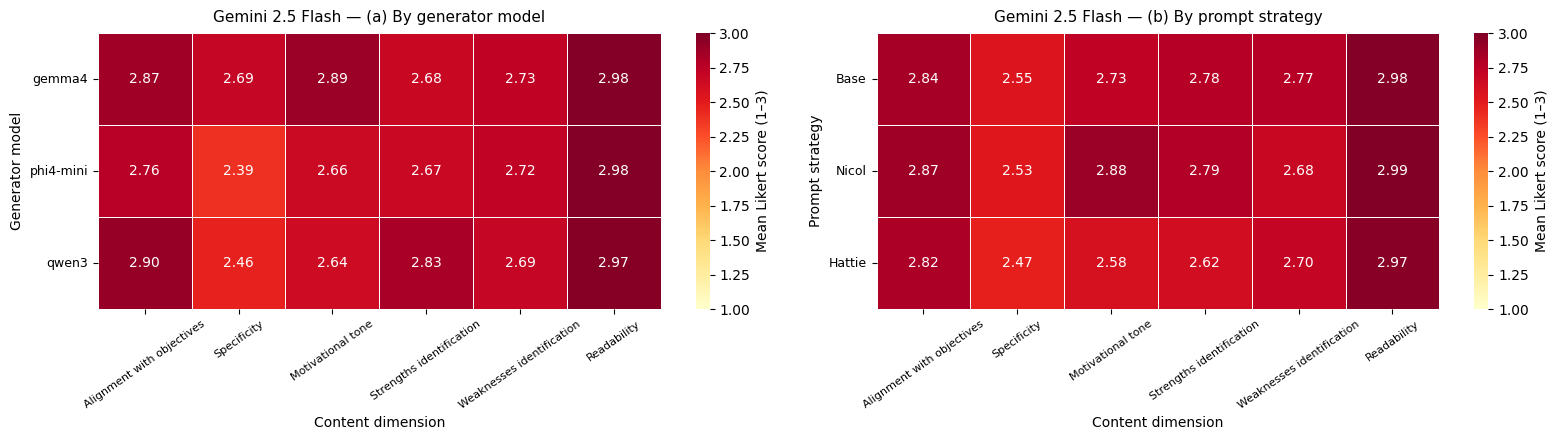


--- GPT-5-mini ---


,Alignment with objectives,Specificity,Motivational tone,Strengths identification,Weaknesses identification,Readability
modelo,,,,,,
gemma4,2.93,2.35,2.95,2.67,2.92,2.99
phi4-mini,2.87,2.15,2.84,2.55,2.88,2.99
qwen3,2.93,2.15,2.92,2.73,2.81,2.98


,Alignment with objectives,Specificity,Motivational tone,Strengths identification,Weaknesses identification,Readability
prompt,,,,,,
Base,2.91,2.26,2.94,2.72,2.90,2.99
Nicol,2.92,2.21,2.96,2.64,2.84,2.99
Hattie,2.90,2.18,2.82,2.59,2.88,2.98


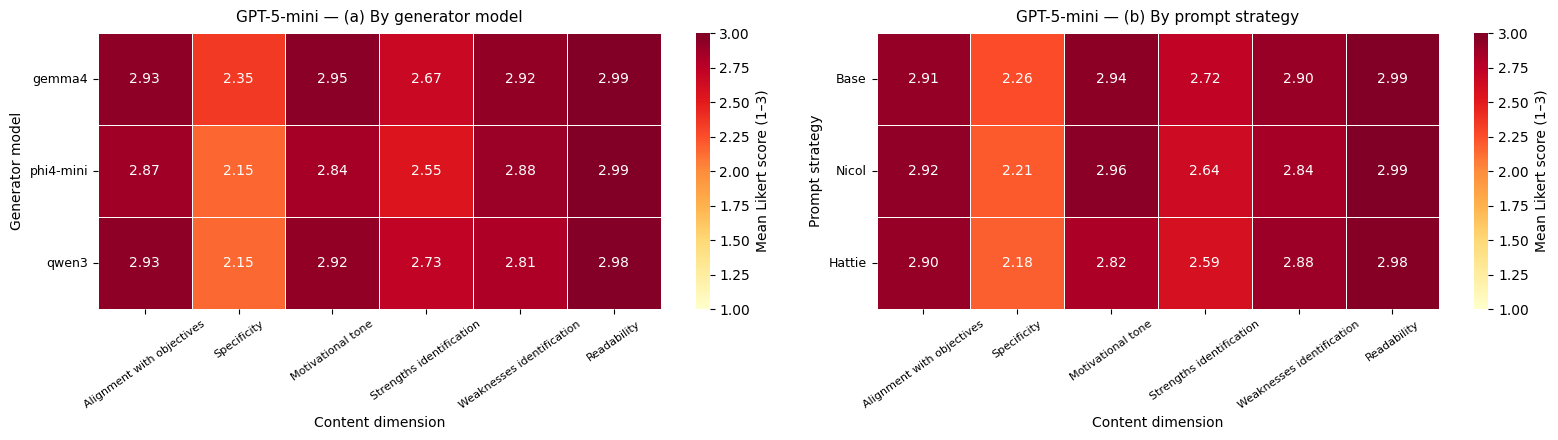

In [20]:
scores = df["analise_feedback"].apply(extrair_scores_conteudo_likert)

linhas = []
for idx, sc in scores.items():
    if sc is None:
        continue
    row = df.loc[idx]
    for dim, likert in sc.items():
        linhas.append(
            {
                "juiz": row["juiz"],
                "modelo": row["modelo"],
                "prompt_variant": row["prompt_variant"],
                "dimensao": dim,
                "likert": likert,
            }
        )

df_long = pd.DataFrame(linhas)
df_long["prompt"] = df_long["prompt_variant"].map(ROTULO_PROMPT)

print("Observações long format:", len(df_long))
print(df_long.groupby("juiz").size())

for juiz in sorted(df_long["juiz"].unique()):
    sub = df_long[df_long["juiz"] == juiz]
    rotulo = ROTULO_JUIZ.get(juiz, juiz)

    pivot_modelo = (
        sub.groupby(["modelo", "dimensao"])["likert"]
        .mean()
        .unstack("dimensao")[DIMENSOES_CONTEUDO]
    )
    pivot_modelo.columns = [ROTULOS_DIMENSAO[c] for c in pivot_modelo.columns]

    pivot_prompt = (
        sub.groupby(["prompt", "dimensao"])["likert"]
        .mean()
        .unstack("dimensao")[DIMENSOES_CONTEUDO]
        .reindex(["Base", "Nicol", "Hattie"])
    )
    pivot_prompt.columns = [ROTULOS_DIMENSAO[c] for c in pivot_prompt.columns]

    print(f"\n--- {rotulo} ---")
    display(pivot_modelo.round(2))
    display(pivot_prompt.round(2))

    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    heatmap_conteudo(
        pivot_modelo,
        f"{rotulo} — (a) By generator model",
        axes[0],
        ylabel="Generator model",
    )
    heatmap_conteudo(
        pivot_prompt,
        f"{rotulo} — (b) By prompt strategy",
        axes[1],
        ylabel="Prompt strategy",
    )
    plt.tight_layout()
    plt.show()

## Overall heatmaps — mean Likert (1–3), both evaluators pooled

Likert observations (both evaluators): 16488


,Alignment with objectives,Specificity,Motivational tone,Strengths identification,Weaknesses identification,Readability
modelo,,,,,,
gemma4,2.90,2.50,2.92,2.67,2.83,2.98
phi4-mini,2.82,2.26,2.76,2.60,2.81,2.98
qwen3,2.92,2.29,2.79,2.77,2.76,2.98


,Alignment with objectives,Specificity,Motivational tone,Strengths identification,Weaknesses identification,Readability
prompt,,,,,,
Base,2.88,2.39,2.85,2.75,2.84,2.98
Nicol,2.90,2.35,2.92,2.71,2.76,2.99
Hattie,2.86,2.31,2.71,2.61,2.80,2.97


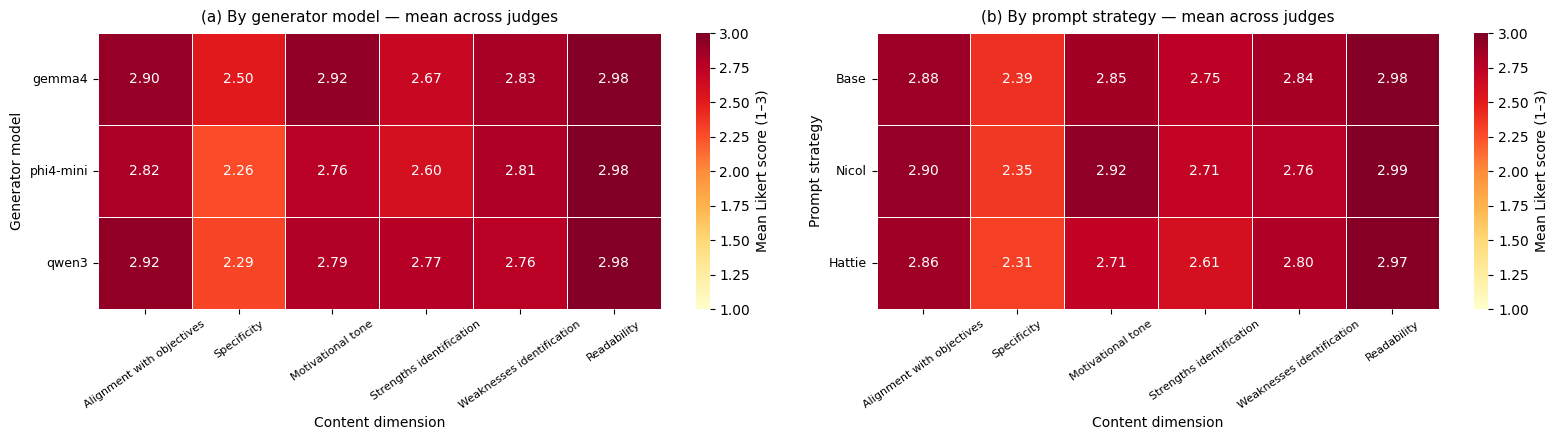

In [21]:
scores_geral = df["analise_feedback"].apply(extrair_scores_conteudo_likert)
linhas_geral = []
for idx, sc in scores_geral.items():
    if sc is None:
        continue
    row = df.loc[idx]
    for dim, likert in sc.items():
        linhas_geral.append(
            {
                "modelo": row["modelo"],
                "prompt_variant": row["prompt_variant"],
                "dimensao": dim,
                "likert": likert,
            }
        )
df_long_geral = pd.DataFrame(linhas_geral)
df_long_geral["prompt"] = df_long_geral["prompt_variant"].map(ROTULO_PROMPT)

pivot_likert_modelo = pivot_likert(df_long_geral, "modelo")
pivot_likert_prompt = pivot_likert(df_long_geral, "prompt")

print(f"Likert observations (both evaluators): {len(df_long_geral)}")
display(pivot_likert_modelo.round(2))
display(pivot_likert_prompt.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
heatmap_conteudo(
    pivot_likert_modelo,
    "(a) By generator model — mean across judges",
    axes[0],
    ylabel="Generator model",
)
heatmap_conteudo(
    pivot_likert_prompt,
    "(b) By prompt strategy — mean across judges",
    axes[1],
    ylabel="Prompt strategy",
)
plt.tight_layout()
plt.show()